In [65]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/rjmanoj/credit-card-customer-churn-prediction/Churn_Modelling.csv


In [66]:
df=pd.read_csv("/kaggle/input/datasets/rjmanoj/credit-card-customer-churn-prediction/Churn_Modelling.csv")

In [67]:
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [68]:
df.shape


(10000, 14)

In [69]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), object(3)
memory usage: 1.1+ MB


In [70]:
df.duplicated().sum()

np.int64(0)

In [71]:
df.isnull().sum()

RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64

In [72]:
df['Exited'].value_counts()

Exited
0    7963
1    2037
Name: count, dtype: int64

In [73]:
df['Geography'].value_counts()

Geography
France     5014
Germany    2509
Spain      2477
Name: count, dtype: int64

In [74]:
df['Gender'].value_counts()

Gender
Male      5457
Female    4543
Name: count, dtype: int64

In [75]:
df[df['Age']<21]["Age"].value_counts()

Age
20    40
19    27
18    22
Name: count, dtype: int64

In [76]:
df[df['Age']>40]["Age"].value_counts()

Age
41    366
42    321
43    297
44    257
45    229
46    226
47    175
48    168
49    147
50    134
51    119
52    102
54     84
55     82
57     75
53     74
56     70
58     67
59     62
60     62
61     53
62     52
63     40
64     37
67     37
66     35
71     27
69     22
72     21
68     19
74     18
65     18
70     18
73     13
76     11
77     10
75      9
78      5
79      4
81      4
80      3
92      2
84      2
82      1
88      1
85      1
83      1
Name: count, dtype: int64

In [77]:
(df['Age']>21).sum()

np.int64(9858)

In [78]:
df[df["Tenure"]>5]["Tenure"].value_counts()

Tenure
7     1028
8     1025
9      984
6      967
10     490
Name: count, dtype: int64

In [79]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), object(3)
memory usage: 1.1+ MB


In [80]:
df.head(2)

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0


In [81]:
df['Tenure'].value_counts()

Tenure
2     1048
1     1035
7     1028
8     1025
5     1012
3     1009
4      989
9      984
6      967
10     490
0      413
Name: count, dtype: int64

In [82]:
df[df["Tenure"]>5]["Tenure"].value_counts()

Tenure
7     1028
8     1025
9      984
6      967
10     490
Name: count, dtype: int64

In [83]:
df.drop(columns=["RowNumber","CustomerId","Surname"],inplace=True)

In [84]:
df.head(2)

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0


In [85]:
df=pd.get_dummies(df,columns=["Geography",'Gender'],drop_first=True,dtype=int) # encoding

In [86]:
df.head(2)

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Geography_Germany,Geography_Spain,Gender_Male
0,619,42,2,0.00,1,1,1,101348.88,1,0,0,0
1,608,41,1,83807.86,1,0,1,112542.58,0,0,1,0


In [87]:
df

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Geography_Germany,Geography_Spain,Gender_Male
0,619,42,2,0.00,1,1,1,101348.88,1,0,0,0
1,608,41,1,83807.86,1,0,1,112542.58,0,0,1,0
2,502,42,8,159660.80,3,1,0,113931.57,1,0,0,0
3,699,39,1,0.00,2,0,0,93826.63,0,0,0,0
4,850,43,2,125510.82,1,1,1,79084.10,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...
9995,771,39,5,0.00,2,1,0,96270.64,0,0,0,1
9996,516,35,10,57369.61,1,1,1,101699.77,0,0,0,1
9997,709,36,7,0.00,1,0,1,42085.58,1,0,0,0
9998,772,42,3,75075.31,2,1,0,92888.52,1,1,0,1


In [90]:
X=df.drop(columns=['Exited'])
Y=df['Exited']
#scalling spliting
from sklearn.model_selection import train_test_split
X_train,X_test,Y_train,Y_test= train_test_split(X,Y,test_size=0.2,random_state=1)

In [92]:
X_train.shape

(8000, 11)

In [93]:
Y_train

2694    0
5140    0
2568    1
3671    0
7427    0
       ..
2895    0
7813    1
905     1
5192    0
235     1
Name: Exited, Length: 8000, dtype: int64

In [94]:
Y_train.shape

(8000,)

In [96]:
# scalling
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
X_train_scaled=scaler.fit_transform(X_train)
X_test_scaled=scaler.transform(X_test)

In [97]:
X_train_scaled

array([[-0.23082038, -0.94449979, -0.70174202, ...,  1.71490137,
        -0.57273139,  0.91509065],
       [-0.25150912, -0.94449979, -0.35520275, ..., -0.58312392,
        -0.57273139, -1.09278791],
       [-0.3963303 ,  0.77498705,  0.33787579, ...,  1.71490137,
        -0.57273139, -1.09278791],
       ...,
       [ 0.22433188,  0.58393295,  1.3774936 , ..., -0.58312392,
        -0.57273139, -1.09278791],
       [ 0.13123255,  0.01077067,  1.03095433, ..., -0.58312392,
        -0.57273139, -1.09278791],
       [ 1.1656695 ,  0.29735181,  0.33787579, ...,  1.71490137,
        -0.57273139,  0.91509065]])

In [98]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import Sequential
from  tensorflow.keras.layers import Dense

In [114]:
model=Sequential()
model.add(Dense(11,activation="relu",input_dim=11)) # rlu or u can increase the no of layer 
model.add(Dense(11,activation="relu"))
model.add(Dense(1,activation="sigmoid"))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [115]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 11)             │           132 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 11)             │           132 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │            12 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 276 (1.08 KB)

 Trainable params: 276 (1.08 KB)

 Non-trainable params: 0 (0.00 B)

In [116]:
# compile karne time hm batna padta hai kyna sa loss function use karo ge 
model.compile(loss="binary_crossentropy",optimizer='Adam',metrics=["accuracy"])

In [125]:
history=model.fit(X_train_scaled,Y_train,epochs=100,validation_split=0.2)

Epoch 1/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8695 - loss: 0.3179 - val_accuracy: 0.8469 - val_loss: 0.3535
Epoch 2/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8705 - loss: 0.3180 - val_accuracy: 0.8494 - val_loss: 0.3529
Epoch 3/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8709 - loss: 0.3177 - val_accuracy: 0.8494 - val_loss: 0.3507
Epoch 4/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8686 - loss: 0.3174 - val_accuracy: 0.8494 - val_loss: 0.3519
Epoch 5/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8694 - loss: 0.3174 - val_accuracy: 0.8469 - val_loss: 0.3520
Epoch 6/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8703 - loss: 0.3174 - val_accuracy: 0.8500 - val_loss: 0.3520
Epoch 7/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8705 - loss: 0.3165 - val_accuracy: 0.8500 - val_loss: 0.3538
Epoch 8/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8711 - loss: 0.3178 - val_accu

In [118]:
# agar hamne model me dekhna  hai ki kitne weight and bias use hua hai o bhi dekh sakte hai 
model.layers[0].get_weights()  # for 1st layer 11 input 3 bais to total weight=11*3=33

[array([[-5.73569417e-01,  1.81575850e-01, -6.19531035e-01,
         -1.27023421e-02,  1.22372143e-01,  2.56844878e-01,
         -1.63275033e-01, -1.34573340e-01, -9.25224721e-02,
         -4.00050014e-01,  7.37431869e-02],
        [ 1.82618171e-01, -7.19299138e-01, -5.27336299e-01,
          4.64095145e-01,  1.85344413e-01, -1.17617890e-01,
          2.01787114e-01,  1.51016498e+00, -5.70237815e-01,
          5.55284321e-02,  2.94703096e-01],
        [-2.19294861e-01, -8.19856972e-02,  9.64450184e-03,
          1.76387191e-01, -3.83030862e-01,  4.33705211e-01,
         -2.97586590e-01,  6.71870336e-02, -2.70141333e-01,
         -2.29242474e-01,  4.20647472e-01],
        [-1.38779640e-01,  1.77135825e-01,  3.64028722e-01,
          2.58341551e-01,  4.28367734e-01, -4.30548310e-01,
         -1.52916044e-01, -3.09932500e-01,  1.17253385e-01,
         -2.23975956e-01, -1.16431370e-01],
        [ 1.42927974e-01,  2.00715959e-01, -9.77355465e-02,
          1.21637785e+00,  4.91636386e-03, -

In [119]:
model.layers[1].get_weights()

[array([[-3.87334257e-01,  1.33667141e-03,  4.98773046e-02,
          2.49328747e-01,  5.92719793e-01, -9.42506671e-01,
          2.84859300e-01,  3.34123850e-01, -2.72853017e-01,
         -1.30662918e-01, -2.62479126e-01],
        [ 7.46062398e-01,  2.89586693e-01,  3.94466847e-01,
         -4.93710518e-01, -2.86191478e-02,  1.74221620e-02,
          4.00187403e-01, -3.32727373e-01,  5.64230323e-01,
         -1.55675739e-01,  5.77027118e-03],
        [ 9.41346586e-02,  5.54153264e-01, -2.26150110e-01,
         -2.53292412e-01, -1.63141012e-01,  2.83144414e-01,
         -7.10001171e-01,  2.82128334e-01, -6.64065063e-01,
         -5.40738463e-01, -4.34275270e-01],
        [ 9.50917542e-01, -3.88362169e-01, -8.15870985e-03,
          6.63539648e-01, -1.56339180e+00, -1.60645694e-02,
         -5.56138158e-01,  1.55065149e-01, -3.62630039e-01,
          1.20476391e-02,  1.03099000e+00],
        [-1.10148184e-01,  3.35378170e-01, -4.30882365e-01,
          3.69079918e-01, -1.98005676e-01, -

In [120]:
# perdication
y_log=model.predict(X_test_scaled)

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


# since hmra perdiction me value 0 and 1 ke bitch ka hai kyu hmne sigmoid use kiya hai aur sigmoid i or 0 ka peobability ka value deta hai 
#We use the sigmoid activation function in the output layer for binary classification because it converts the model's output into a value between 0 and 1, which we interpret as the estimated probability of the positive class. We then apply a threshold, commonly 0.5, to obtain the final class prediction

In [122]:
#threshold
y_pred=np.where(y_log>0.5,1,0)

In [123]:
y_pred

array([[0],
       [0],
       [0],
       ...,
       [0],
       [0],
       [0]])

In [124]:
from sklearn.metrics import accuracy_score
accuracy_score(Y_test,y_pred)

0.86

In [126]:
import matplotlib.pyplot as plt


In [127]:
history.history

{'accuracy': [0.8695312738418579,
  0.8704687356948853,
  0.8709375262260437,
  0.8685937523841858,
  0.8693749904632568,
  0.870312511920929,
  0.8704687356948853,
  0.87109375,
  0.8690624833106995,
  0.8714062571525574,
  0.8689062595367432,
  0.8709375262260437,
  0.8692187666893005,
  0.8684375286102295,
  0.8693749904632568,
  0.8695312738418579,
  0.8693749904632568,
  0.8696874976158142,
  0.8707812428474426,
  0.8692187666893005,
  0.8676562309265137,
  0.8698437213897705,
  0.8695312738418579,
  0.8707812428474426,
  0.8690624833106995,
  0.8698437213897705,
  0.8700000047683716,
  0.8693749904632568,
  0.8700000047683716,
  0.8715624809265137,
  0.8706250190734863,
  0.8695312738418579,
  0.8690624833106995,
  0.8709375262260437,
  0.8698437213897705,
  0.8693749904632568,
  0.8706250190734863,
  0.871874988079071,
  0.8684375286102295,
  0.8709375262260437,
  0.8709375262260437,
  0.8704687356948853,
  0.870312511920929,
  0.8721874952316284,
  0.870312511920929,
  0.870625

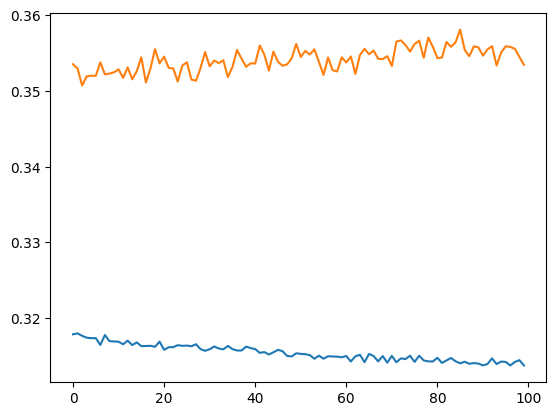

In [129]:
plt.plot(history.history["loss"])
plt.plot(history.history["val_loss"])

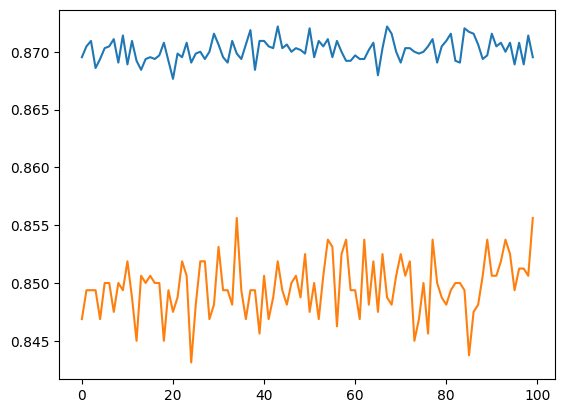

In [130]:
plt.plot(history.history["accuracy"])
plt.plot(history.history["val_accuracy"])